## Exp 2: Training dataset size 

In [1]:
%pip install -q QuantLib numpy pandas scipy scikit-learn torch matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy 
import json 
import platform 
import random 
import time 
from pathlib import Path 

import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
import torch 
from scipy.stats import qmc 
from sklearn.preprocessing import StandardScaler
from torch import nn 

#failchecker 
try: 
    import QuantLib as ql
except ImportError as exc: 
    raise ImportError(
        'QuantLib is required for the actual Heston labels '
        'Uncommment and run the %pip installation cell above, then retry'
    ) from exc

In [3]:
#config carried from #exp 1 
FEATURES = ['S0', 'K', 'T', 'r', 'v0', 'kappa', 'theta', 'sigma', 'rho']
BOUNDS = {
    'S0':(0.6, 1.4),
    'T': (0.1, 1.4),
    'r': (0.0, 0.1),
    'v0': (0.05, 0.5),
    'kappa': (0.0, 2.0),
    'theta': (0.0, 0.5),
    'sigma': (0.0, 0.5),
    'rho': (-0.95, 0.0)
}
VARIABLE_FEATURES = list(BOUNDS)
K_FIXED, Q_FIXED, SEED = 1.0, 0.0, 42
TRAIN_SIZES = (250, 500, 1000, 2000, 4000, 8000, 12000)
BASE_TRAIN_N, VALIDATION_N, TEST_N = 1000, 200, 500
EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE, HIDDEN_UNITS, INTEGRATION_ORDER = 1000, 100, 64, 1e-3, (128,128,128),128

MODEL_SEED = (42, 43, 44)

OUTPUT_DIR = Path('experiment_training_size_results')
DATA_DIR = OUTPUT_DIR / 'data'
HISTORY_DIR = OUTPUT_DIR / 'histories'
MODEL_DIR = OUTPUT_DIR / 'models'
PREDICTION_DIR = OUTPUT_DIR / 'predictions'
FIGURE_DIR = OUTPUT_DIR / 'figures'
for directory in (OUTPUT_DIR, DATA_DIR, HISTORY_DIR, MODEL_DIR, PREDICTION_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BASELINE_RESULTS_DIR = Path('experiment_baseline')


DEVICE = torch.device('cpu')
torch.set_num_threads(min(4, torch.get_num_threads()))
print('Torch:', torch.__version__, '| QuantLib:', getattr(ql, '__version__', 'unknown'))
print('Training sizes:', TRAIN_SIZES)

Torch: 1.12.1 | QuantLib: 1.43
Training sizes: (250, 500, 1000, 2000, 4000, 8000, 12000)


In [4]:
def sample_parameters(n, seed):
    unit = qmc.LatinHypercube(d=len(VARIABLE_FEATURES), seed=seed).random(n)
    lo = np.array([BOUNDS[k][0] for k in VARIABLE_FEATURES])
    hi = np.array([BOUNDS[k][1] for k in VARIABLE_FEATURES])
    df = pd.DataFrame(qmc.scale(unit, lo, hi), columns=VARIABLE_FEATURES)
    df['K'] = K_FIXED
    df['T'] = np.maximum(1, np.round(df['T'] * 365).astype(int))/365.0
    return df[FEATURES]

In [5]:
def heston_reference_price(row): 
    valuation = ql.Date(2, ql.January, 2026)
    ql.Settings.instance().evaluationDate = valuation 
    day_count = ql.Actual365Fixed()
    maturity = valuation + max(1, int(round(float(row['T']) * 365)))
    rf = ql.YieldTermStructureHandle(ql.FlatForward(valuation, float(row['r']), day_count))
    div = ql.YieldTermStructureHandle(ql.FlatForward(valuation, Q_FIXED, day_count))
    spot = ql.QuoteHandle(ql.SimpleQuote(float(row['S0'])))
    process = ql.HestonProcess(rf, div, spot, float(row['v0']), float(row['kappa']), float(row['theta']), float(row['sigma']), float(row['rho']))
    model = ql.HestonModel(process)
    option = ql.VanillaOption(ql.PlainVanillaPayoff(ql.Option.Call, float(row['K'])), ql.EuropeanExercise(maturity))
    option.setPricingEngine(ql.AnalyticHestonEngine(model, INTEGRATION_ORDER))
    return float(option.NPV())

In [6]:
def create_data(n, seed, name):
    df = sample_parameters(n,seed)
    t0 = time.perf_counter()
    prices = []
    for i, row in enumerate(df.to_dict('records'), start=1):
        prices.append(heston_reference_price(row))
        if i % 1000 == 0 or i == n:
            print(f'{name}: priced {i:,}/{n:,} '
                  f'({time.perf_counter()-t0:.1f} s elapsed)')
    df['price'] = prices
    return df

In [7]:
def check_data(df, name):
    required = FEATURES + ['price']
    missing = [c for c in required if c not in df.columns]
    if missing: 
        raise ValueError(f'{name}: Missing columns: {missing}')
    if not np.isfinite(df[required].to_numpy(dtype=float)).all():
        raise ValueError(f'{name}: Non-finite data detected')
    if (df['price'] < -1e-7).any(): 
        raise ValueError(f'{name}: Materially negative reference prices detected')
    lower = np.maximum(df['S0'] - df['K'] * np.exp(-df['r'] * df['T']),0.0)
    if (df['price'] < lower - 1e-4).any() or (df['price'] > df['S0'] + 1e-4).any():
        raise ValueError(f'{name}: Option prices violate no-arbitrage bounds')
    if df[FEATURES].duplicated().any():
        raise ValueError(f"{name}:Duplicate parameter combinations in a dataset")

In [8]:
def load_or_generate(name, n, seed, baseline_name=None):
    cache_path = DATA_DIR/f'{name}.csv'
    if baseline_name: 
        baseline_path = BASELINE_RESULTS_DIR / f'{baseline_name}.csv'
        df = pd.read_csv(baseline_path)
    elif cache_path.exists(): 
        df = pd.read_csv(cache_path)
    else: 
        df = create_data(n, seed, name)
        check_data(df, name)
        df.to_csv(cache_path, index=False) 
    if len(df) != n: 
        raise ValueError(f'{name}: Expected {n} rows, found {len(df)}')
    check_data(df, name)
    return df[FEATURES + ['price']].reset_index(drop=True)


In [9]:
base_train = load_or_generate('base_train_1000', 1000, 42, baseline_name='train')
validation = load_or_generate('validation_200', 200, 43, baseline_name='validation')
test = load_or_generate('test_500', 500, 44, baseline_name='test')

extension = load_or_generate('extension_11000', 11000, 45)
train_pool = pd.concat([base_train,extension], ignore_index=True)
check_data(train_pool, 'full training pool')

all_inputs = pd.concat([
    train_pool[FEATURES], validation[FEATURES], test[FEATURES]
], ignore_index=True)
assert not all_inputs.duplicated().any(), 'Data leakage: repeated inputs across partitions'
assert len(train_pool) == max(TRAIN_SIZES)

subset_order = np.random.default_rng(2026).permutation(BASE_TRAIN_N)
def training_indices(n): 
    if n < BASE_TRAIN_N: 
        return np.sort(subset_order[:n])
    return np.arange(n, dtype=int)

def get_training_frame(n): 
    return train_pool.iloc[training_indices(n)].copy().reset_index(drop=True)

for smaller, larger in zip(TRAIN_SIZES[:-1], TRAIN_SIZES[1:]): 
    assert set(training_indices(smaller)).issubset(set(training_indices(larger)))

for n in TRAIN_SIZES: 
    pd.DataFrame({'training_pool_row_index': training_indices(n)}).to_csv(
        DATA_DIR / f'training_indices_{n}.csv', index=False
    )
print('Validated: all seven training sets nested with separate fixed validation and test sets.')

Validated: all seven training sets nested with separate fixed validation and test sets.


In [10]:
class MLP(nn.Module): 
    def __init__(self):
        super().__init__()
        layers = []
        width = len(FEATURES)
        for hidden_width in HIDDEN_UNITS: 
            layers.extend([nn.Linear(width, hidden_width), nn.ReLU()])
            width = hidden_width
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
    def forward(self,x):
        return self.net(x)

In [11]:
def metrics(actual, pred): 
    actual = np.asarray(actual, dtype=float).ravel()
    pred = np.asarray(pred, dtype=float).ravel()
    error = pred - actual 
    absolute = np.abs(error)
    valid = actual >= 0.01
    return {
        'mae': float(np.mean(absolute)), 
        'rmse': float(np.sqrt(np.mean(error**2))),
        'median_absolute_error': float(np.median(absolute)), 
        'p90_absolute_error': float(np.percentile(absolute, 90)), 
        'max_absolute_error': float(np.max(absolute)), 
        'relative_error_percent_on_prices_above_0_01': (
            float(100 * np.mean(absolute[valid]/actual[valid]))
            if np.any(valid) else None
        ),
    }

In [12]:
def fit_and_evaluate(train, validation, test, n, model_seed): 
    random.seed(model_seed)
    np.random.seed(model_seed)
    torch.manual_seed(model_seed)

    x_scaler = StandardScaler().fit(train[FEATURES].to_numpy())
    y_scaler = StandardScaler().fit(train[['price']].to_numpy())

    def tensor_data(frame):
        x = torch.tensor(x_scaler.transform(frame[FEATURES].to_numpy()), dtype=torch.float32)
        y = torch.tensor(y_scaler.transform(frame[['price']].to_numpy()), dtype=torch.float32)
        return x, y 
    
    xtr, ytr = tensor_data(train)
    xva, yva = tensor_data(validation)
    xte, _ = tensor_data(test)

    net = MLP().to(DEVICE)
    optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    best_loss = float('inf')
    best_state, best_epoch = None, None 
    stale = 0 
    history = []
    start = time.perf_counter()

    for epoch in range(1, EPOCHS+1): 
        net.train()
        perm = torch.randperm(len(xtr))
        for indices in perm.split(BATCH_SIZE): 
            optimizer.zero_grad()
            loss = criterion(net(xtr[indices]), ytr[indices])
            loss.backward()
            optimizer.step()
        net.eval()
        with torch.inference_mode(): 
            train_loss = criterion(net(xtr), ytr).item()
            val_loss = criterion(net(xva), yva).item()
        history.append({
            'train_n': n, 
            'model_seed': model_seed, 
            'epoch': epoch, 
            'train_mse_scaled': train_loss, 
            'validation_mse_scaled': val_loss
        })
        if val_loss < best_loss - 1e-7: 
            best_loss = val_loss 
            best_epoch = epoch 
            best_state = copy.deepcopy(net.state_dict())
            stale=0
        else: 
            stale += 1
        if epoch % 100 == 0:
            print(f' n={n:5,d} seed={model_seed} epoch={epoch:4d}: ' 
                  f'train MSE={train_loss:.6f}, validation MSE={val_loss:.6f}')
        if stale >= PATIENCE: 
            break 

    training_seconds = time.perf_counter() - start 
    if best_state is None: 
        raise RuntimeError('No valid checkpoint was obtained')
    net.load_state_dict(best_state)
    net.eval()

    with torch.inference_mode():
        prediction = y_scaler.inverse_transform(net(xte).cpu().numpy()).ravel() 
    
    actual = test['price'].to_numpy(dtype=float)
    results = metrics(actual, prediction)
    results.update({
        'train_n': n, 
        'validation_n': len(validation), 
        'test_n': len(test), 
        'model_seed': model_seed, 
        'best_epoch': best_epoch, 
        'epochs_ran': len(history), 
        'best_validation_mse_scaled': float(best_loss), 
        'training_seconds': float(training_seconds), 
        'parameter_count': sum(p.numel() for p in net.parameters()),
    })

    with torch.inference_mode(): 
        for _ in range(20): 
            net(xte)
        timings = []
        for _ in range(100): 
            t0 = time.perf_counter()
            net(xte)
            timings.append(time.perf_counter() - t0)
    results['median_batch_inference_ms_500'] = 1000.0 * float(np.median(timings))
    results['median_inference_microseconds_per_option_batched'] = (
        1e6 * float(np.median(timings)) / len(test)
    )

    predictions = test.copy()
    predictions['predicted_price'] = prediction 
    predictions['absolute_error'] = np.abs(prediction - actual)
    predictions['train_n'] = n 
    predictions['model_seed'] = model_seed

    checkpoint = {
        'model_state_dict': net.state_dict(), 
        'features': FEATURES, 
        'hidden_units': HIDDEN_UNITS, 
        'x_mean': x_scaler.mean_, 'x_scale': x_scaler.scale_, 
        'y_mean': y_scaler.mean_, 'y_scale': y_scaler.scale_, 
        'bounds': BOUNDS, 
        'model_seed': model_seed, 
        'train_n': n,  
    }
    return results, pd.DataFrame(history), predictions, checkpoint

In [13]:
FORCE_RETAIN = False
trail_results = []

for n in TRAIN_SIZES: 
    train = get_training_frame(n) 
    check_data(train, f'train_{n}')
    for model_seed in MODEL_SEED: 
        stem = f'n{n}_seed{model_seed}'
        result_path = OUTPUT_DIR / f'metrics_{stem}.json'
        history_path = HISTORY_DIR / f'history_{stem}.csv'
        predictions_path = PREDICTION_DIR / f'test_prediction_{stem}.csv'
        checkpoint_path = MODEL_DIR / f'model_{stem}.pt'
        all_present = all(p.exists() for p in (
            result_path, history_path, predictions_path, checkpoint_path
        ))
        if all_present and not FORCE_RETAIN: 
            print(f'Reusing completed run: {stem}')
            result = json.loads(result_path.read_text(encoding='utf-8'))
        else: 
            print(f'\nTraining with {n:,} samples (seed {model_seed}) ...')
            result, history, predictions, checkpoint = fit_and_evaluate(
                train, validation, test, n, model_seed
            )
            history.to_csv(history_path, index=False)
            predictions.to_csv(predictions_path, index=False)
            torch.save(checkpoint, checkpoint_path)
            result_path.write_text(json.dumps(result, indent=2),encoding='utf-8')
            print(f'Finished n={n:,}: test MAE={result["mae"]:.6f}',
                  f'RMSE={result["rmse"]:.6f}, '
                  f'train={result["training_seconds"]:.2f} s, '
                  f'best epoch={result["best_epoch"]}')
        trail_results.append(result)
trials = pd.DataFrame(trail_results).sort_values(['train_n', 'model_seed'])
trials.to_csv(OUTPUT_DIR / 'training_size_trials.csv', index=False)

metric_cols = [
    'mae', 'rmse', 'median_absolute_error', 'p90_absolute_error', 
    'max_absolute_error', 'relative_error_percent_on_prices_above_0_01',
    'training_seconds', 'best_epoch', 'epochs_ran', 
    'median_batch_inference_ms_500', 
    'median_inference_microseconds_per_option_batched', 
]

summary = trials.groupby('train_n', as_index=False).agg(
    repeats = ('model_seed', 'count'), 
    **{f'{m}_mean': (m, 'mean') for m in metric_cols}, 
    **{f'{m}_std': (m, 'std') for m in metric_cols},
)

summary.to_csv(OUTPUT_DIR/'training_size_summary.csv', index=False)


totsum = {
    'experiment': 2, 
    'reseach_question': 'RQ5', 
    'varied_factor': 'number of training samples', 
    'train_sizes': list(TRAIN_SIZES), 
    'model_seeds': list(MODEL_SEED), 
    'validation_n': VALIDATION_N, 
    'test_n': TEST_N, 
    'baseline_train_n': BASE_TRAIN_N, 
    'training_selection': 'nested subsets of Exp1 first 1000 + LHS(seed=45) extension', 
    'baseline_LHS_seed': 42, 
    'validation_LHS_seed': 43, 
    'total_LHS_seed': 44, 
    'extension_LHS_seed': 45, 
    'subset_seed': 2026, 
    'architecture': list(HIDDEN_UNITS), 
    'learning_rate': LEARNING_RATE, 
    'batch_size': BATCH_SIZE, 
    'max_epochs': EPOCHS, 
    'early_stopping_patience': PATIENCE, 
    'reference_pricer': 'QuantLib AnalyticHestonEngine', 
    'integration_order': INTEGRATION_ORDER, 
    'features': FEATURES, 
    'bounds': BOUNDS, 
    'K_FIXED': K_FIXED, 
    'Q_FIXED': Q_FIXED, 
    'versions':{
        'python': platform.python_version(), 
        'numpy': np.__version__, 
        'pandas': pd.__version__, 
        'torch': torch.__version__, 
        'quantlib': str(getattr(ql, '__version__', 'unknown'))
    }, 
}
(OUTPUT_DIR / 'experiment_config.json').write_text(json.dumps(totsum, indent=2), encoding='utf-8')

print('\nEXPERIMENT 2 - OUT-OF-SAMPLE RESULTS')
print(trials[[
    'train_n', 'model_seed', 'mae', 'rmse', 'p90_absolute_error', 
    'max_absolute_error', 'training_seconds', 'best_epoch'
]].to_string(index=False, float_format=lambda v:f'{v:.6f}'))
print(f'\nFiles saved to: {OUTPUT_DIR.resolve()}')

Reusing completed run: n250_seed42
Reusing completed run: n250_seed43
Reusing completed run: n250_seed44
Reusing completed run: n500_seed42
Reusing completed run: n500_seed43
Reusing completed run: n500_seed44
Reusing completed run: n1000_seed42
Reusing completed run: n1000_seed43
Reusing completed run: n1000_seed44
Reusing completed run: n2000_seed42
Reusing completed run: n2000_seed43
Reusing completed run: n2000_seed44
Reusing completed run: n4000_seed42
Reusing completed run: n4000_seed43
Reusing completed run: n4000_seed44
Reusing completed run: n8000_seed42
Reusing completed run: n8000_seed43
Reusing completed run: n8000_seed44
Reusing completed run: n12000_seed42
Reusing completed run: n12000_seed43
Reusing completed run: n12000_seed44

EXPERIMENT 2 - OUT-OF-SAMPLE RESULTS
 train_n  model_seed      mae     rmse  p90_absolute_error  max_absolute_error  training_seconds  best_epoch
     250          42 0.010231 0.013756            0.022243            0.052952          9.956994    

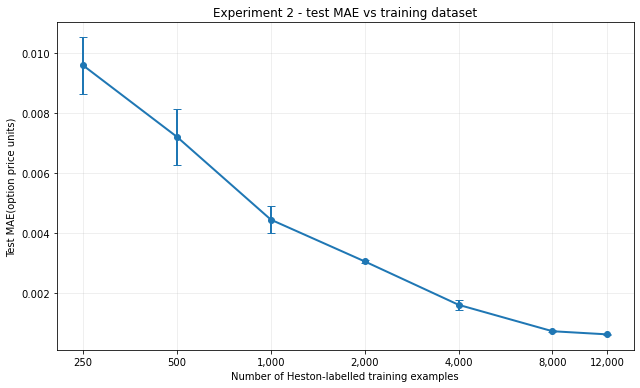

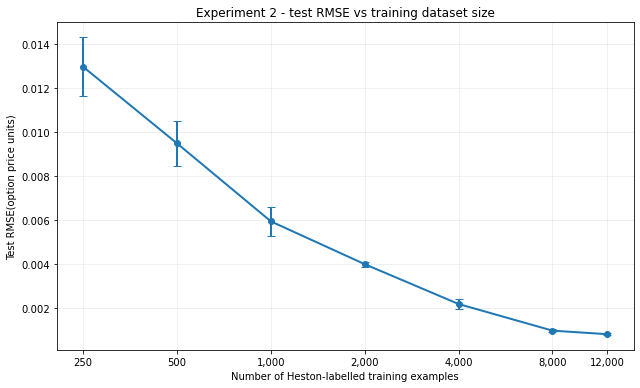

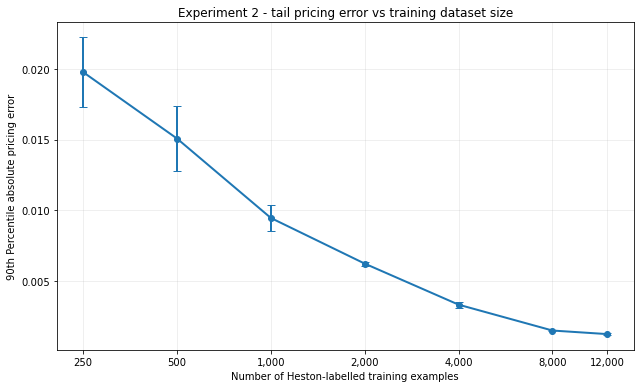

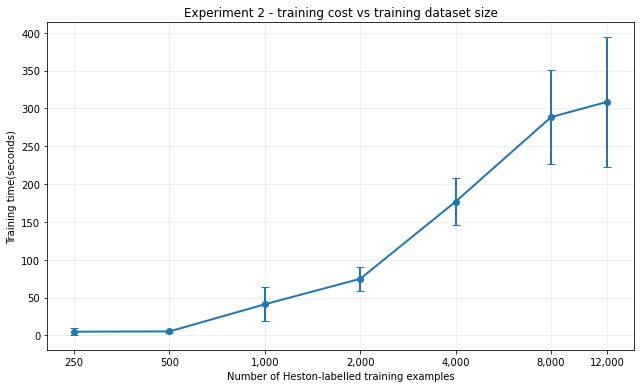

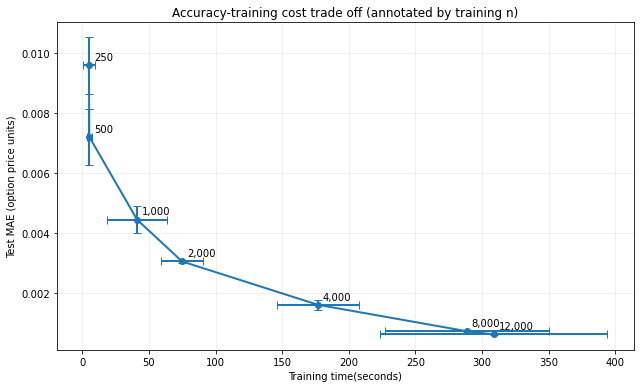

In [14]:
plot_data = summary.sort_values('train_n')
x = plot_data['train_n'].to_numpy()

def plot_metric(y_column, ylabel, title, filename, log_y=False): 
    fig, ax = plt.subplots(figsize=(9,5.5))
    std_column = y_column.replace('_mean', '_std')
    ax.errorbar(
        x, 
        plot_data[y_column].to_numpy(), 
        yerr = plot_data[std_column].to_numpy(), 
        marker='o', 
        linewidth=2, 
        capsize=4
    )
    ax.set_xscale('log', base=2)
    if log_y: 
        ax.set_yscale('log')
    ax.set_xticks(x)
    ax.set_xticklabels([f'{v:,}' for v in x])
    ax.set_xlabel('Number of Heston-labelled training examples')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)
plot_metric('mae_mean', 'Test MAE(option price units)', 
            'Experiment 2 - test MAE vs training dataset',
            'test_mae_vs_training_size.png')
plot_metric('rmse_mean', 'Test RMSE(option price units)', 
            'Experiment 2 - test RMSE vs training dataset size',
            'test_rmse_vs_training_size.png')
plot_metric('p90_absolute_error_mean', '90th Percentile absolute pricing error',
            'Experiment 2 - tail pricing error vs training dataset size', 
            'test_p90error_vs_training_size.png')
plot_metric('training_seconds_mean', 'Training time(seconds)', 
            'Experiment 2 - training cost vs training dataset size',
            'training_seconds_vs_training_size.png')

fig, ax = plt.subplots(figsize=(9,5.5))
ax.errorbar(
    plot_data['training_seconds_mean'].to_numpy(), 
    plot_data['mae_mean'].to_numpy(), 
    xerr = plot_data['training_seconds_std'].to_numpy(), 
    yerr= plot_data['mae_std'].to_numpy(), 
    marker='o',
    linewidth=2, 
    capsize=4
)

for row in plot_data.itertuples(index=False): 
    ax.annotate(
        f'{row.train_n:,}', 
        (row.training_seconds_mean, row.mae_mean), 
        textcoords='offset points', 
        xytext=(5,5)
    )
ax.set_xlabel('Training time(seconds)')
ax.set_ylabel('Test MAE (option price units)')
ax.set_title('Accuracy-training cost trade off (annotated by training n)')
ax.grid(alpha=0.25)
fig.tight_layout(), 
fig.savefig(FIGURE_DIR / 'mae_vs_training_cost.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)
    

In [15]:
report = summary[['train_n', 'repeats', 'mae_mean', 'rmse_mean', 
                  'p90_absolute_error_mean', 'training_seconds_mean', 'best_epoch_mean',
                  'mae_std', 'rmse_std', 'p90_absolute_error_std', 'training_seconds_std']].copy()
report.columns = ['train_n', 'repeats', 'test_MAE', 'test_RMSE', 
                  'test_P90_abs_error', 'training_seconds', 'best_epoch',
                  'test_MAE_std', 'test_RMSE_std', 'test_P90_abs_error_std', 'training_seconds_std']
report['MAE_change_vs_previous_percent'] = report['test_MAE'].pct_change() * 100


print(report.to_string(index=False, float_format=lambda v: f'{v:.6f}'))
print(f'\nBest observed test MAE: {report["test_MAE"].min():.6f}')
print(f'Test MAE reduction: 250 -> 12000 = '
      f'{100 * (1 - report.iloc[-1].test_MAE / report.iloc[0].test_MAE):.2f}%')

report.to_csv(OUTPUT_DIR / 'RQ5_summary_table.csv', index=False)

 train_n  repeats  test_MAE  test_RMSE  test_P90_abs_error  training_seconds  best_epoch  test_MAE_std  test_RMSE_std  test_P90_abs_error_std  training_seconds_std  MAE_change_vs_previous_percent
     250        3  0.009594   0.012971            0.019758          4.998642  160.666667      0.000941       0.001346                0.002461              4.294059                             NaN
     500        3  0.007209   0.009488            0.015069          5.322610  202.000000      0.000948       0.001031                0.002279              2.071920                      -24.864970
    1000        3  0.004445   0.005937            0.009462         41.165388  968.333333      0.000448       0.000649                0.000895             22.364203                      -38.343453
    2000        3  0.003051   0.003987            0.006240         74.868822  597.000000      0.000061       0.000105                0.000138             15.704446                      -31.365649
    4000        3  0